<a href="https://colab.research.google.com/github/Shreyas-Reddy707/Machine-Learning/blob/main/Machine_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

```markdown
# 🏡 Real Estate Valuation & Price Prediction Engine

## 📌 Project Overview
This project aims to build an end-to-end Machine Learning pipeline to predict house prices based on physical and locational attributes. This is developed as a student project for **Machine Learning** to demonstrate:
- Synthetic data creation reflecting realistic non-linear relations.
- Exploratory Data Analysis (EDA) & Feature Importance analysis.
- Rigorous model evaluation using advanced ensemble techniques (**Random Forest** and **Gradient Boosting**).
- Hyperparameter optimization with `GridSearchCV`.
- Robust feature engineering and scaling wrapped cleanly inside industry-standard **Scikit-Learn Pipelines** with cross-validation.

## 📊 Feature Specifications
- **Area**: Total built-up area of the house in square feet.
- **Bedrooms**: Number of bedroom units.
- **Bathrooms**: Number of bathroom units.
- **Location_Rating**: Subjective location premium rating (scale: 1-10).
- **Age**: Age of the property in years (affects depreciation).
- **Nearby_Amenities**: Count of primary facilities (schools, hospitals, etc.) nearby.
- **Price (Target)**: Estimated market value of the home in INR (₹).
```

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

```markdown
## 🛠️ Phase 1: Libraries Installation & Setup
We initialize the environment by importing standard mathematical, manipulation, and modeling utilities.
```

In [2]:
np.random.seed(42)
num_samples = 500

df = pd.DataFrame({
    'Area': np.random.randint(500, 4000, num_samples),
    'Bedrooms': np.random.randint(1, 6, num_samples),
    'Bathrooms': np.random.randint(1, 5, num_samples),
    'Location_Rating': np.random.randint(1, 10, num_samples),
    'Age': np.random.randint(1, 30, num_samples),
    'Nearby_Amenities': np.random.randint(1, 15, num_samples)
})

df['Price'] = (
    df['Area'] * np.random.uniform(2500, 4500) +
    df['Bedrooms'] * 180000 +
    df['Bathrooms'] * 150000 +
    df['Location_Rating'] * 200000 -
    df['Age'] * 45000 +
    df['Nearby_Amenities'] * 60000 +
    np.random.randint(-500000, 500000, num_samples)
).astype(int)

df.head()

,Area,Bedrooms,Bathrooms,Location_Rating,Age,Nearby_Amenities,Price
0,3674,4,4,1,2,5,15463239
1,1360,2,3,9,7,12,7549074
2,1794,3,2,8,6,6,9378777
3,1630,4,2,2,17,4,6313780
4,1595,5,4,9,27,2,7727358


```markdown
## 🎲 Phase 2: Synthetic Dataset Generation
To simulate real-world market dynamics, we synthesize 500 records utilizing controlled random coefficients and noise factors.
```

In [3]:
print(df.head())
print("\nDataset Info:")
print(df.info())
print("\nMissing Values:")
print(df.isnull().sum())

   Area  Bedrooms  Bathrooms  Location_Rating  Age  Nearby_Amenities     Price
0  3674         4          4                1    2                 5  15463239
1  1360         2          3                9    7                12   7549074
2  1794         3          2                8    6                 6   9378777
3  1630         4          2                2   17                 4   6313780
4  1595         5          4                9   27                 2   7727358

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Area              500 non-null    int64
 1   Bedrooms          500 non-null    int64
 2   Bathrooms         500 non-null    int64
 3   Location_Rating   500 non-null    int64
 4   Age               500 non-null    int64
 5   Nearby_Amenities  500 non-null    int64
 6   Price             500 non-null    int64
dt

```markdown
## 🔍 Phase 3: Dataset Splitting & Target Isolation
We partition the attributes into features (`X`) and our target vector (`y`), followed by splitting into Training (80%) and Testing (20%) subsets.
```

In [4]:
X = df.drop('Price', axis=1)
y = df['Price']

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

In [6]:
model = DecisionTreeRegressor(max_depth=7, random_state=42)
model.fit(X_train, y_train)

DecisionTreeRegressor(max_depth=7, random_state=42)

```markdown
## 🌳 Phase 4: Baseline Model Training
We begin by fitting a standard **Decision Tree Regressor** to establish our performance baseline.
```

In [7]:
y_pred = model.predict(X_test)

In [8]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error (MAE):", mae)
print("Mean Squared Error (MSE):", mse)
print("Root Mean Squared Error (RMSE):", rmse)
print("R² Score:", r2)

Mean Absolute Error (MAE): 626687.4521677489
Mean Squared Error (MSE): 638617573310.7528
Root Mean Squared Error (RMSE): 799135.5162366098
R² Score: 0.9491583213630645


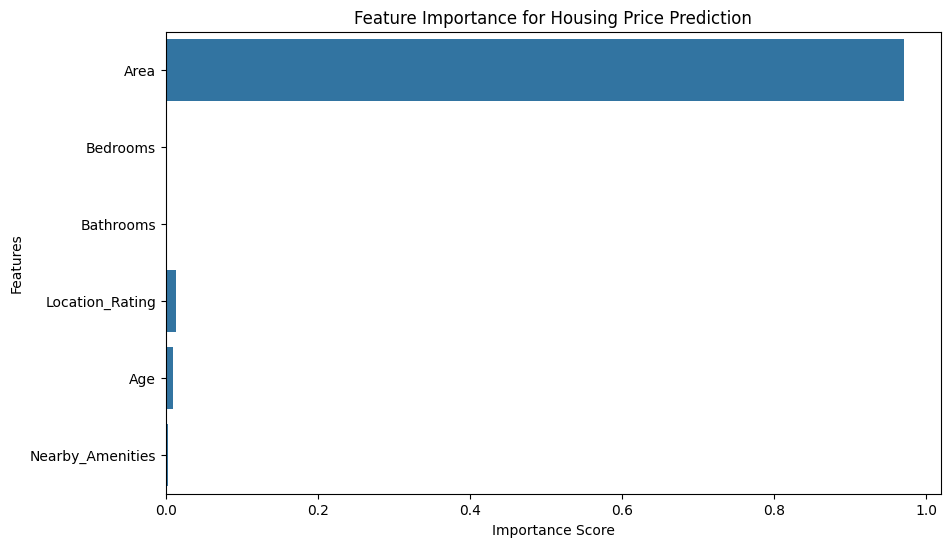

In [9]:
plt.figure(figsize=(10,6))
sns.barplot(x=model.feature_importances_, y=X.columns)
plt.title("Feature Importance for Housing Price Prediction")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.show()

```markdown
## 🔮 Phase 5: Out-Of-Sample Inference
Testing our baseline model's predictive capability on unseen data using a customized manual test scenario.
```

In [10]:
new_house = pd.DataFrame({
    'Area': [2400],
    'Bedrooms': [3],
    'Bathrooms': [2],
    'Location_Rating': [8],
    'Age': [5],
    'Nearby_Amenities': [7]
})

predicted_price = model.predict(new_house)
print("Predicted House Price: ₹", int(predicted_price[0]))

Predicted House Price: ₹ 11080074


### 🚀 Portfolio Upgrades: Advanced Ensemble Models & Hyperparameter Tuning

To turn this into a robust machine learning project, we will:
1. Compare multiple models: **Decision Tree**, **Random Forest**, and **Gradient Boosting**.
2. Perform hyperparameter optimization using **Grid Search**.
3. Compare metrics ($R^2$, $MAE$, $RMSE$) side-by-side.
4. Visualize performance comparison.

In [11]:
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import GridSearchCV

# Initialize models for comparison
models = {
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'Random Forest': RandomForestRegressor(random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42)
}

# Define hyperparameter grid for Random Forest as a showcase of tuning
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [5, 10, 15],
    'min_samples_split': [2, 5, 10]
}

print("Optimizing Random Forest via Grid Search...")
grid_search = GridSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1
)
grid_search.fit(X_train, y_train)

best_rf = grid_search.best_estimator_
print(f"Best Hyperparameters for Random Forest: {grid_search.best_params_}")

Optimizing Random Forest via Grid Search...
Best Hyperparameters for Random Forest: {'max_depth': 15, 'min_samples_split': 2, 'n_estimators': 200}


In [12]:
# Update our comparison models to include the tuned model
tuned_models = {
    'Decision Tree (Base)': model,
    'Random Forest (Tuned)': best_rf,
    'Gradient Boosting (Base)': GradientBoostingRegressor(random_state=42).fit(X_train, y_train)
}

# Evaluate and store results
results = []
for name, clf in tuned_models.items():
    predictions = clf.predict(X_test)
    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    results.append({
        'Model': name,
        'MAE': mae,
        'RMSE': rmse,
        'R2 Score': r2
    })

results_df = pd.DataFrame(results)
display(results_df.sort_values(by='R2 Score', ascending=False))

,Model,MAE,RMSE,R2 Score
2,Gradient Boosting (Base),320323.239775,423031.890677,0.985753
1,Random Forest (Tuned),420673.069763,540194.713899,0.976768
0,Decision Tree (Base),626687.452168,799135.516237,0.949158


/tmp/ipykernel_809/465286661.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='R2 Score', y='Model', data=results_df.sort_values(by='R2 Score', ascending=False), palette='viridis')


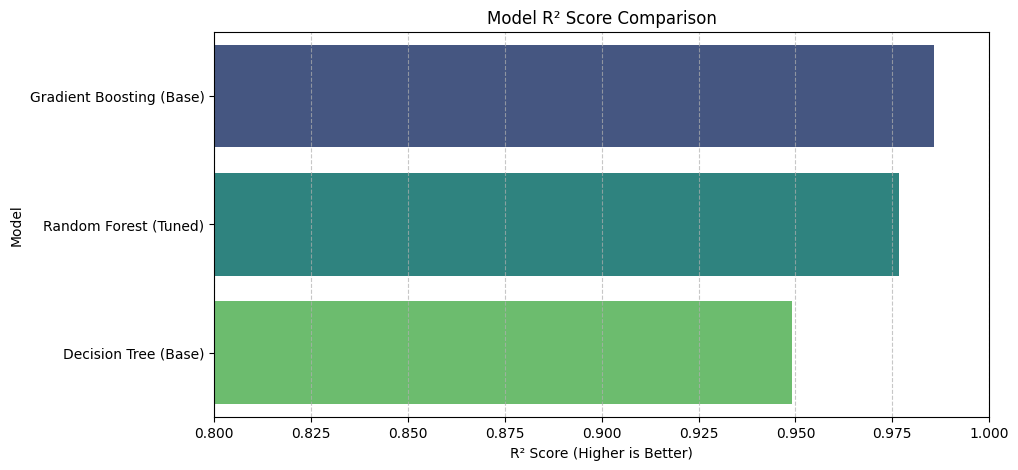

In [13]:
# Visualize Model Performance Comparison
plt.figure(figsize=(10, 5))
sns.barplot(x='R2 Score', y='Model', data=results_df.sort_values(by='R2 Score', ascending=False), palette='viridis')
plt.title('Model R² Score Comparison')
plt.xlabel('R² Score (Higher is Better)')
plt.xlim(0.8, 1.0)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

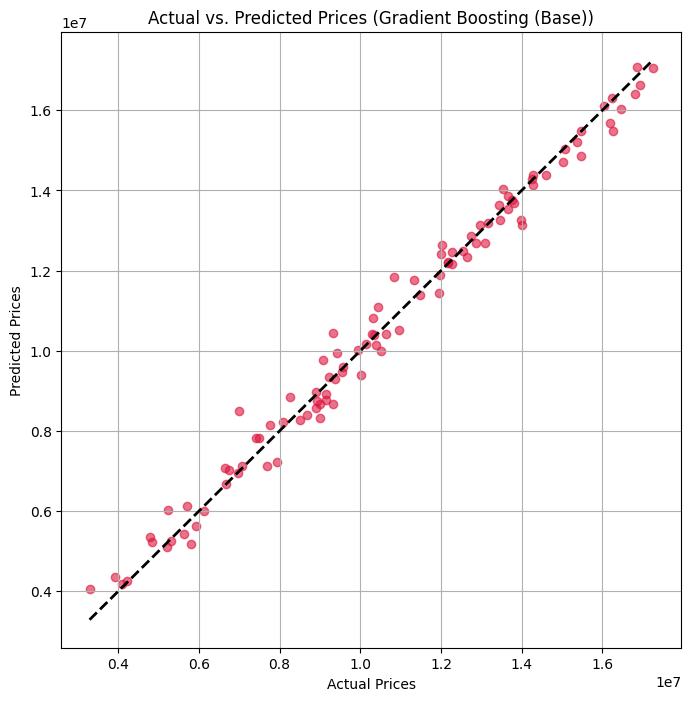

In [14]:
# Plot Predictions vs Actual for the Best Model
best_model_name = results_df.sort_values(by='R2 Score', ascending=False).iloc[0]['Model']
best_model = tuned_models[best_model_name]
best_preds = best_model.predict(X_test)

plt.figure(figsize=(8, 8))
plt.scatter(y_test, best_preds, alpha=0.6, color='crimson')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=2)
plt.xlabel('Actual Prices')
plt.ylabel('Predicted Prices')
plt.title(f'Actual vs. Predicted Prices ({best_model_name})')
plt.grid(True)
plt.show()

In [15]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score

# 1. Feature Engineering
def engineer_features(data):
    df_feat = data.copy()
    # Avoid division by zero
    df_feat['Bed_Bath_Ratio'] = df_feat['Bedrooms'] / (df_feat['Bathrooms'] + 0.1)
    df_feat['Area_per_Room'] = df_feat['Area'] / (df_feat['Bedrooms'] + df_feat['Bathrooms'] + 1)
    return df_feat

# Engineer train and test features
X_train_eng = engineer_features(X_train)
X_test_eng = engineer_features(X_test)

# 2. Pipeline Design (Standardization + Estimator)
pipelines = {
    'Decision Tree (Pipeline)': Pipeline([
        ('scaler', StandardScaler()),
        ('regressor', DecisionTreeRegressor(max_depth=7, random_state=42))
    ]),
    'Random Forest (Pipeline)': Pipeline([
        ('scaler', StandardScaler()),
        ('regressor', RandomForestRegressor(n_estimators=200, max_depth=15, random_state=42))
    ]),
    'Gradient Boosting (Pipeline)': Pipeline([
        ('scaler', StandardScaler()),
        ('regressor', GradientBoostingRegressor(random_state=42))
    ])
}

# 3. K-Fold Cross-Validation & Test Evaluation
pipe_results = []
for name, pipe in pipelines.items():
    # Cross-validation
    cv_scores = cross_val_score(pipe, X_train_eng, y_train, cv=5, scoring='r2')

    # Fit on training data
    pipe.fit(X_train_eng, y_train)
    preds = pipe.predict(X_test_eng)

    # Test metrics
    r2 = r2_score(y_test, preds)
    mae = mean_absolute_error(y_test, preds)

    pipe_results.append({
        'Model': name,
        'CV Mean R2': cv_scores.mean(),
        'CV Std R2': cv_scores.std(),
        'Test R2': r2,
        'Test MAE': mae
    })

pipeline_df = pd.DataFrame(pipe_results)
display(pipeline_df.sort_values(by='Test R2', ascending=False))

,Model,CV Mean R2,CV Std R2,Test R2,Test MAE
2,Gradient Boosting (Pipeline),0.987296,0.000838,0.985464,322953.506447
1,Random Forest (Pipeline),0.978276,0.001851,0.975367,435969.164044
0,Decision Tree (Pipeline),0.955020,0.003246,0.944814,675380.560389
